# 1. Ecology and encrypted-AMP richness

Question: do GenomeSPOT temperature, pH, salinity and oxygen-tolerance predictions
explain the rate of high-scoring encrypted AMP sequences after accounting for
screening exposure, proteome size and taxonomy?

**The saved regression outputs use explicitly simulated data.** Actual public
source audits and source-genome predictions are shown separately. Switch to
real mode only with a validated complete screening bundle.

In [1]:
from pathlib import Path
import os, sys, json, platform, subprocess
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/genomespot_lens/amp_study.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from genomespot_lens.amp_study import (
    TRAITS, load_bundle, prepare_cohort, analysis_subset, standardized,
    fit_nb, effect_table, grouped_ecology_cv, tree_covariance,
    build_phylogenetic_nb,
)

# Explicit demonstration mode. Change to "real" only after preparing the contract.
# No automatic fallback to simulated data is permitted.
MODE = os.environ.get("AMP_STUDY_MODE", "demo")
assert MODE in {"demo", "real"}
COHORT = os.environ.get("AMP_STUDY_COHORT", "atb")
DATA_DIR = (ROOT / "examples/amp-study/demo") if MODE == "demo" else Path(
    os.environ.get("AMP_STUDY_DATA", str(ROOT / "data/amp-study")))
RUN_PHYLO_MCMC = os.environ.get("AMP_STUDY_PHYLO_MCMC", "0") == "1"
SEED = 23
LABEL = "SIMULATED DATA — software demonstration" if MODE == "demo" else "REAL COHORT — observational associations"
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
display(Markdown(f"**{LABEL}**"))
print("Python", platform.python_version(), "| cohort:", COHORT, "| bundle:", "examples/amp-study/demo" if MODE == "demo" else DATA_DIR.name)
FIG_DIR = ROOT / "runs/amp-study/figures" / MODE
FIG_DIR.mkdir(parents=True, exist_ok=True)
def save_figure(figure, name):
    figure.savefig(FIG_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    figure.savefig(FIG_DIR / f"{name}.svg", bbox_inches="tight")

**SIMULATED DATA — software demonstration**

Python 3.11.16 | cohort: atb | bundle: examples/amp-study/demo


## Available source data

In [2]:
# Actual published-source audit, independent of the simulated analysis below.
source_audit = json.loads((ROOT / "examples/amp-study/source-audit.json").read_text())
display(pd.DataFrame([
    {"source": "Archaeome complete positive-score catalog", "records": source_audit["archaeome"]["score_rows"], "genome richness ready": False},
    {"source": "Archaeome selected source mappings", "records": source_audit["archaeome"]["selected_mapping_rows"], "genome richness ready": False},
]))
source_dir = ROOT / "examples/amp-study/source-genomes"
if source_dir.exists():
    # Genuine GenomeSPOT outputs. They are not joined to invented AMP counts.
    real_predictions = pd.read_csv(source_dir / "genomespot.csv")
    display(real_predictions[real_predictions.target.isin(TRAITS.values())])
print("Source-screen linkage: see study/source-search.md and study/data-contract.md")

,source,records,genome richness ready
0,Archaeome complete positive-score catalog,12623,False
1,Archaeome selected source mappings,265,False


,genome_id,target,value,error,is_novel,warning,units
0,GCF_000091665.1,temperature_optimum,78.66277683556687,7.414129,False,NaN,C
3,GCF_000091665.1,ph_optimum,5.653625708702203,1.278201,False,NaN,pH
6,GCF_000091665.1,salinity_optimum,1.3394815190900058,1.877941,True,NaN,% w/v NaCl
9,GCF_000091665.1,oxygen,not tolerant,0.999991,True,NaN,probability
10,GCF_000011105.1,temperature_optimum,91.07637426802242,5.791886,False,NaN,C
13,GCF_000011105.1,ph_optimum,6.599838846769681,0.960230,False,NaN,pH
16,GCF_000011105.1,salinity_optimum,0.3534652516594101,1.873083,False,NaN,% w/v NaCl
19,GCF_000011105.1,oxygen,not tolerant,0.997884,False,NaN,probability
20,GCF_000008665.1,temperature_optimum,83.06935213778993,6.773858,False,NaN,C
23,GCF_000008665.1,ph_optimum,6.49814827121021,1.009838,False,NaN,pH


Source-screen linkage: see study/source-search.md and study/data-contract.md


The biological unit is a genome. AMP richness counts **distinct peptide sequences
per genome**, after exact parent/source mapping and a complete scoring panel.
The exposure counts the corresponding distinct sequences screened under one
fixed protocol, model version and target panel. Missing or failed screens remain
missing. Repeated parent copies and multiple target scores do not multiply counts.

Use each dataset/cohort separately. ATB's reported any-target <80 µM rule and the
archaeome study's mean-panel ≤100 µM rule define different outcomes. Preserve the
original rule in `bundle.json`; harmonizing thresholds also requires harmonized
screening and source coverage. Predicted MIC and measured MIC are distinct fields.

In [3]:
tables, spec, provenance, tree_path = load_bundle(DATA_DIR, COHORT, expected_kind=MODE)
cohort, candidate_table, hit_audit = prepare_cohort(tables, spec)
display(pd.Series(hit_audit, name="hit-table audit"))
display(pd.DataFrame({
    "genomes": [len(cohort)],
    "completed_screens": [int(cohort.screen_eligible.sum())],
    "quality_pass": [int(cohort.genome_qc_pass.sum())],
    "all_four_traits_unflagged": [int(cohort.all_traits_unflagged.sum())],
    "amr_successful": [int(cohort.amr_status.eq("PASS").sum())],
}))
assert not cohort.loc[~cohort.screen_eligible, "amp_count"].notna().any()
assert not cohort.loc[~cohort.amr_status.eq("PASS"), "amr_gene_count"].notna().any()

input_rows                            8776
nonexact_rows_excluded                   0
incomplete_panel_peptides_excluded       0
distinct_genome_peptide_hits          4388
Name: hit-table audit, dtype: int64

,genomes,completed_screens,quality_pass,all_four_traits_unflagged,amr_successful
0,384,376,373,374,375


## Primary model and inclusion criteria

Use quality-screened genomes with successful complete AMP screens and unflagged
predictions for all four primary traits. Keep all exclusion reasons. Fit an NB2
count model with log(screened sequences / 100,000) as a fixed offset. Adjust for
proteome amino-acid count, GC fraction, habitat and family fixed effects. Species
clusters provide robust standard errors; the phylogenetic sensitivity model below
adds branch-length-based covariance. The four ecology coefficients form one
prespecified multiple-testing family (Benjamini–Hochberg correction).

An effect is a rate ratio per cohort standard deviation of the predictor, not a
change in organism growth or antimicrobial activity caused by changing habitat.

In [4]:
data, excluded = analysis_subset(cohort, require_traits=True)
traits = [f"trait_{t}" for t in TRAITS]
data, scales = standardized(data, traits + ["gc_fraction", "log_proteome_aa"])
display(pd.Series({"included": len(data), "excluded": len(excluded), "families": data.family.nunique(), "species_clusters": data.species.nunique()}))
display(excluded.head(10))
display(data[traits].corr())
formula = "amp_count ~ " + " + ".join(f"z_{t}" for t in traits) + " + z_gc_fraction + z_log_proteome_aa + C(habitat) + C(family)"
fit = fit_nb(data, formula)
effects = effect_table(fit, [f"z_{t}" for t in traits])
display(effects)
habitat_effects = effect_table(fit, [term for term in fit.params.index if term.startswith("C(habitat)")])
display(habitat_effects)
print("NB2 overdispersion alpha:", fit.params["alpha"])
print("Observed zero fraction:", data.amp_count.eq(0).mean())
print("Predicted zero fraction:", np.mean((1 + fit.params["alpha"] * fit.predict()) ** (-1 / fit.params["alpha"])))

included            357
excluded             27
families             12
species_clusters     48
dtype: int64

,genome_id,screen_eligible,genome_qc_pass,all_traits_unflagged,amr_status
0,SIM_0000,False,False,False,FAIL
37,SIM_0037,True,False,True,PASS
41,SIM_0041,True,True,False,PASS
53,SIM_0053,False,True,True,PASS
74,SIM_0074,True,False,True,PASS
82,SIM_0082,True,True,False,PASS
106,SIM_0106,False,True,True,PASS
111,SIM_0111,True,False,True,PASS
123,SIM_0123,True,True,False,PASS
148,SIM_0148,True,False,True,PASS


,trait_temperature,trait_ph,trait_salinity,trait_oxygen
trait_temperature,1.000000,0.086763,0.208204,-0.095963
trait_ph,0.086763,1.000000,0.002933,-0.016507
trait_salinity,0.208204,0.002933,1.000000,0.063527
trait_oxygen,-0.095963,-0.016507,0.063527,1.000000


,term,log_rate_ratio,rate_ratio,ci_low,ci_high,p_value,q_value_bh
0,z_trait_temperature,0.127081,1.135509,1.029331,1.252639,0.011177,0.044706
1,z_trait_ph,0.050956,1.052276,0.962399,1.150547,0.263307,0.369950
2,z_trait_salinity,-0.046437,0.954624,0.862472,1.056623,0.369950,0.369950
3,z_trait_oxygen,-0.036114,0.964530,0.896072,1.038217,0.336317,0.369950


,term,log_rate_ratio,rate_ratio,ci_low,ci_high,p_value,q_value_bh
0,C(habitat)[T.soil],0.020552,1.020765,0.860922,1.210285,0.813022,0.813022
1,C(habitat)[T.water],0.056920,1.058572,0.893399,1.254281,0.510776,0.813022


NB2 overdispersion alpha: 0.5386027730744346
Observed zero fraction: 0.056022408963585436
Predicted zero fraction: 0.05262014529862502


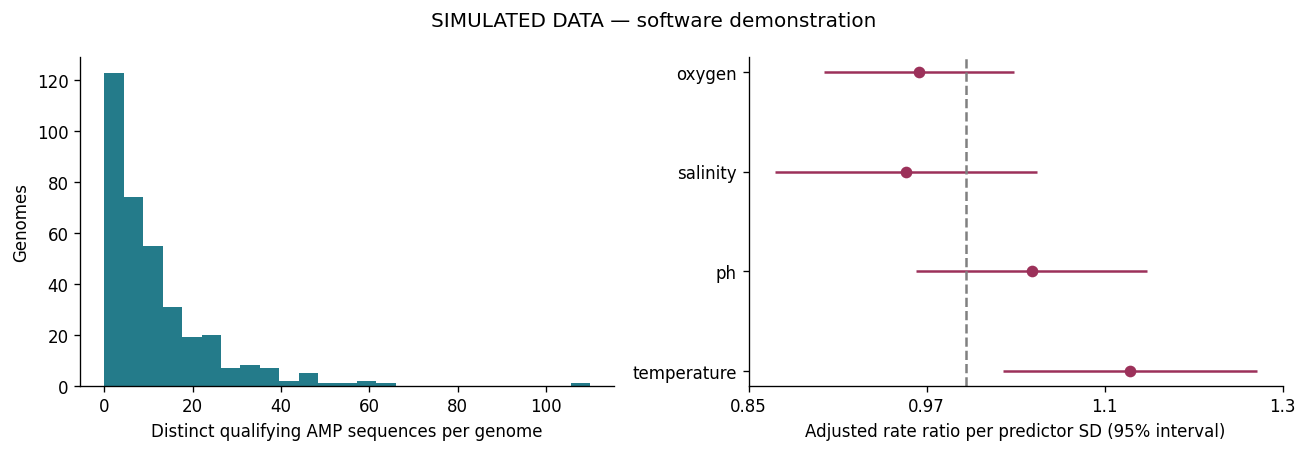

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(data.amp_count, bins=25, color="#247b8a")
axes[0].set(xlabel="Distinct qualifying AMP sequences per genome", ylabel="Genomes")
y = np.arange(len(effects))
axes[1].errorbar(effects.rate_ratio, y, xerr=[effects.rate_ratio-effects.ci_low, effects.ci_high-effects.rate_ratio], fmt="o", color="#9c315a")
axes[1].axvline(1, color="grey", linestyle="--")
axes[1].set_yticks(y, effects.term.str.replace("z_trait_", "", regex=False))
axes[1].set(xlabel="Adjusted rate ratio per predictor SD (95% interval)", xscale="log")
from matplotlib.ticker import FuncFormatter, NullLocator
axes[1].set_xticks(np.geomspace(effects.ci_low.min() * .98, effects.ci_high.max() * 1.02, 4))
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, position: f"{x:.2g}"))
axes[1].xaxis.set_minor_locator(NullLocator())
fig.suptitle(LABEL)
fig.tight_layout()
save_figure(fig, "ecology_primary")
plt.show()

## Prediction beyond taxonomy

Compare a numeric size/GC baseline with size/GC plus the four traits, holding
entire families out. Scaling is estimated using each training fold. Family and
habitat fixed effects are omitted from **both prediction models** so unseen
categories do not enter through fitted labels. Lower held-out Poisson deviance
means better mean prediction; it is not a likelihood test or accuracy of the
underlying GenomeSPOT traits. The two models use identical folds.

In [6]:
cv = grouped_ecology_cv(data)
display(cv)
display(cv.pivot(index="fold", columns="model", values="poisson_deviance"))

,fold,model,test_n,test_families,poisson_deviance
0,0,size_gc,90,SIM_Family_1;SIM_Family_10;SIM_Family_7,8.619239
1,0,size_gc_plus_ecology,90,SIM_Family_1;SIM_Family_10;SIM_Family_7,8.066782
2,1,size_gc,89,SIM_Family_0;SIM_Family_6;SIM_Family_8,6.942308
3,1,size_gc_plus_ecology,89,SIM_Family_0;SIM_Family_6;SIM_Family_8,6.110840
4,2,size_gc,89,SIM_Family_3;SIM_Family_4;SIM_Family_9,8.238168
5,2,size_gc_plus_ecology,89,SIM_Family_3;SIM_Family_4;SIM_Family_9,9.443075
6,3,size_gc,89,SIM_Family_11;SIM_Family_2;SIM_Family_5,13.059603
7,3,size_gc_plus_ecology,89,SIM_Family_11;SIM_Family_2;SIM_Family_5,11.618169


model,size_gc,size_gc_plus_ecology
fold,,
0,8.619239,8.066782
1,6.942308,6.110840
2,8.238168,9.443075
3,13.059603,11.618169


## Sensitivity analyses

Repeat the primary model at a stricter MIC cutoff, and with finite flagged
GenomeSPOT outputs retained. These are sensitivity analyses of the same cohort,
not extra independent discoveries. Missing predictions are never imputed as zero.
If the source table is complete only below the primary threshold, stricter
thresholds are identifiable but looser thresholds are not.

In [7]:
sensitivity_rows = []
strict_spec = {**spec, "threshold_um": spec["threshold_um"] / 2}
strict_cohort, _, _ = prepare_cohort(tables, strict_spec)
for label, input_cohort, keep_flags in [("stricter_cutoff", strict_cohort, False), ("finite_flagged_included", cohort, True)]:
    subset, _ = analysis_subset(input_cohort, require_traits=not keep_flags)
    subset = subset.dropna(subset=traits).reset_index(drop=True)
    subset, _ = standardized(subset, traits + ["gc_fraction", "log_proteome_aa"])
    result = effect_table(fit_nb(subset, formula), [f"z_{t}" for t in traits])
    result["sensitivity"] = label
    result["n"] = len(subset)
    sensitivity_rows.append(result)
sensitivities = pd.concat(sensitivity_rows, ignore_index=True)
display(sensitivities)

,term,log_rate_ratio,rate_ratio,ci_low,ci_high,p_value,q_value_bh,sensitivity,n
0,z_trait_temperature,0.125532,1.133752,1.024929,1.254130,0.014760,0.059040,stricter_cutoff,357
1,z_trait_ph,0.054181,1.055675,0.963513,1.156653,0.245041,0.423116,stricter_cutoff,357
2,z_trait_salinity,-0.048531,0.952628,0.860312,1.054849,0.350718,0.423116,stricter_cutoff,357
3,z_trait_oxygen,-0.030888,0.969584,0.899006,1.045703,0.423116,0.423116,stricter_cutoff,357
4,z_trait_temperature,0.117559,1.124747,1.022009,1.237814,0.016154,0.064615,finite_flagged_included,366
5,z_trait_ph,0.057330,1.059005,0.973542,1.151971,0.181752,0.363504,finite_flagged_included,366
6,z_trait_salinity,-0.037933,0.962778,0.875992,1.058161,0.431266,0.431266,finite_flagged_included,366
7,z_trait_oxygen,-0.030362,0.970094,0.903689,1.041379,0.401337,0.431266,finite_flagged_included,366


## Phylogenetic sensitivity

Use the supplied rooted, branch-length tree rather than a taxonomy dendrogram.
The NB2 mixed model includes a Brownian phylogenetic effect and the same numeric
ecology/size/GC covariates plus habitat. Family fixed effects are omitted here
because the tree accounts for ancestry. The covariance, prior predictive model
and likelihood are exercised below. Posterior sampling is opt-in and checked
for R-hat, effective sample size and divergent transitions.

In [8]:
import patsy
import pymc as pm
if not spec.get("tree_rooted"):
    raise ValueError("A documented rooted tree with branch lengths is required")
phylo_cov = tree_covariance(tree_path, data.genome_id.tolist())
X_phylo = patsy.dmatrix('1 + z_trait_temperature + z_trait_ph + z_trait_salinity + z_trait_oxygen + z_gc_fraction + z_log_proteome_aa + C(habitat)', data, return_type="dataframe", NA_action="raise")
phylo_model = build_phylogenetic_nb(data, X_phylo, phylo_cov)
print("Built phylogenetic negative-binomial model:", len(data), "genomes,", X_phylo.shape[1], "fixed effects")
# A prior-predictive check exercises the actual mixed-model likelihood.
with phylo_model:
    prior_check = pm.sample_prior_predictive(samples=20, random_seed=SEED, var_names=["amp_count"])
print("Prior predictive dimensions:", dict(prior_check.prior_predictive.sizes))
if RUN_PHYLO_MCMC:
    import arviz as az
    with phylo_model:
        phylo_fit = pm.sample(draws=1000, tune=1000, chains=4, cores=2,
                              target_accept=.95, random_seed=SEED,
                              idata_kwargs={"log_likelihood": True})
        posterior_check = pm.sample_posterior_predictive(phylo_fit, random_seed=SEED)
    diagnostics = az.summary(phylo_fit, var_names=["beta", "phylo_sd", "nb_shape"])
    display(diagnostics)
    print("Divergences:", int(phylo_fit.sample_stats.diverging.sum()))
    all_rhat = float(az.rhat(phylo_fit).to_array().max())
    min_bulk_ess = float(az.ess(phylo_fit, method="bulk").to_array().min())
    print("All-parameter maximum R-hat:", all_rhat, "| minimum bulk ESS:", min_bulk_ess)
    az.plot_ppc(posterior_check, num_pp_samples=50)
    plt.suptitle(LABEL + " — posterior predictive check")
    plt.show()
    assert all_rhat < 1.01, "Chains have not converged"
    assert min_bulk_ess >= 400, "Insufficient effective samples"
    assert int(phylo_fit.sample_stats.diverging.sum()) == 0, "Resolve divergences"
    draws = phylo_fit.posterior.beta.stack(sample=("chain", "draw"))
    posterior_effects = pd.DataFrame({
        "coefficient": X_phylo.columns,
        "rate_ratio_median": np.exp(draws.median("sample").values),
        "rate_ratio_q025": np.exp(draws.quantile(.025, dim="sample").values),
        "rate_ratio_q975": np.exp(draws.quantile(.975, dim="sample").values),
    })
    display(posterior_effects)
    (ROOT / "runs").mkdir(exist_ok=True)
    phylo_fit.to_netcdf(ROOT / "runs" / ("ecology_phylo_" + MODE + ".nc"))
    posterior_effects.to_csv(ROOT / "runs" / ("ecology_phylo_effects_" + MODE + ".csv"), index=False)
else:
    print("Posterior MCMC was NOT run. Enable AMP_STUDY_PHYLO_MCMC=1 for posterior estimates.")

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Built phylogenetic negative-binomial model: 357 genomes, 9 fixed effects


Sampling: [amp_count, beta, nb_shape, phylo_sd, phylo_z]


Prior predictive dimensions: {'chain': 1, 'draw': 20, 'genome': 357}
Posterior MCMC was NOT run. Enable AMP_STUDY_PHYLO_MCMC=1 for posterior estimates.


In [9]:
OUT = ROOT / "runs/amp-study/ecology" / MODE
OUT.mkdir(parents=True, exist_ok=True)
data.to_csv(OUT / "cohort.csv", index=False)
excluded.to_csv(OUT / "excluded.csv", index=False)
effects.to_csv(OUT / "effects.csv", index=False)
habitat_effects.to_csv(OUT / "habitat_effects.csv", index=False)
cv.to_csv(OUT / "cross_validation.csv", index=False)
sensitivities.to_csv(OUT / "sensitivities.csv", index=False)
provenance["analysis"] = "ecology"
provenance["seed"] = SEED
provenance["run_phylogenetic_mcmc"] = RUN_PHYLO_MCMC
provenance["git_commit"] = subprocess.check_output(["git", "-C", str(ROOT), "rev-parse", "HEAD"], text=True).strip()
provenance["git_dirty"] = bool(subprocess.check_output(["git", "-C", str(ROOT), "status", "--porcelain"], text=True).strip())
provenance["bundle_settings"] = spec
provenance["packages"] = {p: version(p) for p in ["numpy", "pandas", "statsmodels", "pymc", "arviz", "biopython", "nbformat", "nbclient"]}
from genomespot_lens.core import sha256
provenance["analysis_code_sha256"] = {str(p.relative_to(ROOT)): sha256(p) for p in [ROOT / "src/genomespot_lens/amp_study.py", ROOT / "scripts/build_study_notebooks.py"]}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
print("Saved results:", OUT.relative_to(ROOT))
display(Markdown("**Demonstration complete; simulated coefficients are not biological findings.**"
                 if MODE == "demo" else "**Review diagnostics, exclusions and sensitivity analyses before interpreting associations.**"))

Saved results: runs/amp-study/ecology/demo


**Demonstration complete; simulated coefficients are not biological findings.**

## Interpretation and limits

Ask whether effects are stable across cutoffs, taxa, flags and family-held-out
prediction. Report effect sizes and intervals, including null results. GenomeSPOT
traits describe predicted growth preferences, not measured habitat conditions.
Protein composition contributes to both physiology and AMP prediction, so a
correlation may reflect shared model inputs. Before a biological claim, add
composition/screen-coverage controls and independent strain-resolved measurements.
Measurement-error sensitivity cannot treat local cross-validation RMSE as a
calibrated per-genome confidence interval.

Sources and methods:

- [GenomeSPOT paper](https://doi.org/10.1101/2024.03.22.586313)
- [AllTheBacteria paper](https://doi.org/10.1101/2024.03.08.584059)
- [Archaeome paper](https://doi.org/10.1038/s41564-025-02061-0) and
  [Mendeley data deposit](https://doi.org/10.17632/d8yzgtdrcp.3)
- [AMR annotation documentation](https://allthebacteria.org/docs/amr/)
- [ATB phylogeny documentation](https://allthebacteria.org/docs/phylogeny/)
- [Negative-binomial likelihood](https://www.pymc.io/projects/docs/en/v5.10.4/api/distributions/generated/pymc.NegativeBinomial.html)

See `study/data-contract.md`, `study/analysis-plan.md` and `study/source-search.md`
for input definitions, reproducibility, exclusions and remaining source gaps.